# 01 – Portafolio
**Lab #2 – Derivados Financieros** · Puntos 1 a 5 (proceso de creación del portafolio: 20 % + R5 y R6)

## Importar librerías

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import yfinance as yf

RAW = Path("../data/raw")
PROC = Path("../data/processed")

## Punto 1 – Análisis fundamental (R1 – 5 %)

**Cabe aclarar que las acciones seleccionadas se eligieron por decisiones de los integrantes del grupo de forma aleatoria sin tener en cuenta análisis fundamental. Sin embargo, a continuación se realiza el análisis fundamental de por qué no cambiamos tales acciones.**

,Precio 30/10/2026,Máx 52s,Mín 52s,Dist. al máx,Ret. precio YTD,Ret. total 1a,Ret. total 3a,Ret. total 5a
ADI,417.11,445.48,225.20,-6.4%,53.8%,81.3%,180.4%,161.4%
CSCO,104.51,130.00,71.04,-19.6%,35.7%,46.0%,118.6%,114.1%
PYPL,57.01,69.27,39.08,-17.7%,-2.3%,-15.1%,12.9%,-75.2%
^NDX,"28,384.85","31,224.47","22,953.38",-9.1%,12.4%,10.3%,98.0%,79.1%


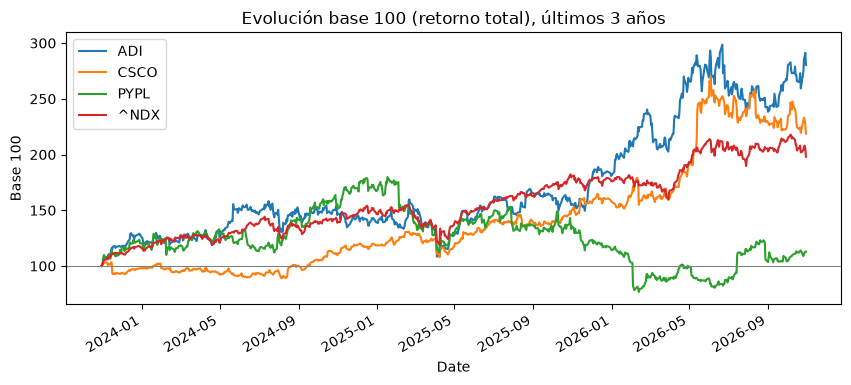

In [10]:
def leer_precios(nombre):
    df = pd.read_csv(RAW / nombre, index_col=0)                    # lee el CSV con la fecha como índice
    df = df[pd.to_datetime(df.index, errors="coerce").notna()]    # descarta filas de encabezado extra que deja yfinance
    df.index = pd.to_datetime(df.index)                           # convierte el índice a fechas
    return df.astype(float)                                       # asegura que los precios sean numéricos

close = leer_precios("close_diario.csv")      # precios sin ajustar (retorno de precio)
adj = leer_precios("adjclose_diario.csv")     # precios ajustados (retorno total)
f = close.index[-1]                           # fecha de inicio de la inversión: 30/10/2026

def ret(df, años):                                        # retorno entre hace N años y hoy
    p0 = df.loc[:f - pd.DateOffset(years=años)].iloc[-1]  # último precio disponible hace N años
    return df.iloc[-1] / p0 - 1                           # Pₜ / P₀ − 1

ult_año = close.loc[f - pd.DateOffset(years=1):]          # ventana de 52 semanas
evol = pd.DataFrame({
    "Precio 30/10/2026": close.iloc[-1],
    "Máx 52s": ult_año.max(),
    "Mín 52s": ult_año.min(),
    "Dist. al máx": close.iloc[-1] / ult_año.max() - 1,             # % por debajo del máximo
    "Ret. precio YTD": close.iloc[-1] / close.loc[:"2025-12-31"].iloc[-1] - 1,
    "Ret. total 1a": ret(adj, 1),
    "Ret. total 3a": ret(adj, 3),
    "Ret. total 5a": ret(adj, 5),
})
display(evol.style.format({"Precio 30/10/2026": "{:,.2f}", "Máx 52s": "{:,.2f}",
                           "Mín 52s": "{:,.2f}"}, precision=2).format(
        "{:.1%}", subset=evol.columns[3:]))                       # tabla con formato

base100 = adj.loc[f - pd.DateOffset(years=3):]                    # últimos 3 años
(base100 / base100.iloc[0] * 100).plot(figsize=(10, 4),
        title="Evolución base 100 (retorno total), últimos 3 años")
plt.axhline(100, color="grey", lw=0.8); plt.ylabel("Base 100"); plt.show()

**Análisis evolución del precio:** Al analizar la evolución del precio, ADI y CSCO superaron al Nasdaq-100 en los tres periodos medidos. ADI rindió 81.3 % en un año, 180.4 % en tres y 161.4 % en cinco, frente a 10.3 %, 98.0 % y 79.1 % del índice. CSCO obtuvo 46.0 %, 118.6 % y 114.1 %. PYPL quedó por debajo en todos los plazos: −15.1 % a un año, 12.9 % a tres y −75.2 % a cinco. El gráfico muestra, que entre finales de 2024 y comienzos de 2025 PYPL estuvo por encima del índice, antes de una caída sostenida que la llevó a ser la única con retorno anual negativo.

In [18]:
acciones = ["CSCO", "ADI", "PYPL"]
campos = {                                       # campo de Yahoo: (nombre en la tabla, formato)
    "sector": ("Sector", "txt"), "industry": ("Industria", "txt"),
    "marketCap": ("Cap. bursátil (USD M)", "usd"), "totalRevenue": ("Ingresos 12m (USD M)", "usd"),
    "revenueGrowth": ("Crec. ingresos a/a", "pct"), "grossMargins": ("Margen bruto", "pct"),
    "operatingMargins": ("Margen operativo", "pct"), "profitMargins": ("Margen neto", "pct"),
    "returnOnEquity": ("ROE", "pct"), "freeCashflow": ("Flujo de caja libre 12m (USD M)", "usd"),
    "totalCash": ("Caja (USD M)", "usd"), "totalDebt": ("Deuda (USD M)", "usd"),
    "currentRatio": ("Razón corriente", "num"), "dividendRate": ("Dividendo anual (USD)", "num"),
}
info = {t: yf.Ticker(t).info for t in acciones}                      # foto de Yahoo a la fecha de consulta
fund = pd.DataFrame({t: {k: info[t].get(k) for k in campos} for t in acciones})
num = lambda k: pd.to_numeric(fund.loc[k], errors="coerce")           # convierte una fila a número
precio = close.iloc[-1][acciones]                                     # precio al 30/10/2026
fund.loc["netCash"] = num("totalCash") - num("totalDebt")             # > 0: más caja que deuda
fund.loc["divYield"] = num("dividendRate") / precio                   # dividendo anual / precio
campos.update({"netCash": ("Caja neta (USD M)", "usd"), "divYield": ("Rend. dividendo", "pct")})
fund.to_csv(PROC / "fundamentales_yahoo.csv")                         # evidencia: Yahoo cambia a diario

def fmt(v, tipo):                                 # formato: miles con coma y decimales con punto
    if v is None or (not isinstance(v, str) and pd.isna(v)): return "–"
    if tipo == "usd": return f"{float(v)/1e6:,.0f}"                  # millones de USD: 63,300
    if tipo == "pct": return f"{float(v):.1%}"                       # porcentaje: 16.3%
    if tipo == "num": return f"{float(v):,.2f}"                      # número: 1,234.56
    return v                                                          # texto (sector, industria)

tabla_12 = pd.DataFrame({t: [fmt(fund.at[k, t], f) for k, (_, f) in campos.items()] for t in acciones},
                        index=[n for n, _ in campos.values()])
print(f"{'=' * 82}\n{'SITUACIÓN FINANCIERA':^82}\n{'=' * 82}\nFuente: Yahoo Finance, consultado el {pd.Timestamp.today().date()}")
display(tabla_12)

                               SITUACIÓN FINANCIERA                               
Fuente: Yahoo Finance, consultado el 2026-11-01


,CSCO,ADI,PYPL
Sector,Technology,Technology,Financial Services
Industria,Communication Equipment,Semiconductors,Credit Services
Cap. bursátil (USD M),"412,040","202,117","47,356"
Ingresos 12m (USD M),"63,325","13,882","34,295"
Crec. ingresos a/a,17.6%,39.6%,2.0%
Margen bruto,64.5%,65.8%,40.5%
Margen operativo,27.7%,39.5%,18.4%
Margen neto,21.0%,29.8%,13.8%
ROE,27.3%,12.2%,23.8%
Flujo de caja libre 12m (USD M),"11,183","4,147","4,487"


#### Tabla de análisis fundamental

| Elemento | CSCO – Cisco Systems | ADI – Analog Devices | PYPL – PayPal |
|---|---|---|---|
| **Descripción** | Líder mundial en equipos de redes y ciberseguridad.| Fabricante de chips que conectan el mundo físico con el digital.| Plataforma de pagos digitales (PayPal, Venmo, Braintree).|
| **Sector** | Tecnología · Equipos de comunicación | Tecnología · Semiconductores | Servicios financieros · Servicios de crédito (en la práctica, pagos digitales) |
| **Fuentes de ingresos** | Más de la mitad de lo que vende son los equipos que conectan las redes de empresas y centros de datos. El resto viene de ciberseguridad, herramientas de colaboración y contratos de soporte, que le dan ingresos estables año tras año. | Vende chips que convierten temperatura, sonido, energía o movimiento en datos. Casi la mitad de sus ventas va a la industria (fábricas, defensa, equipos de medición); el resto, a carros, centros de datos y electrónica de consumo. | Cobra una pequeña comisión por cada pago que procesa: eso es el 90 % de sus ingresos. El 10 % restante viene de créditos a consumidores e intereses sobre el dinero que los clientes prestan. |
| **Evolución del precio** | +46.0 % en un año, pero 19.6 % por debajo de su máximo: subió con los pedidos de IA (may-2026) y cayó 9 % tras resultados (ago-2026) por temor a menor crecimiento. | +81.3 % en un año y cerca de su máximo (−6.4 %), impulsada por la recuperación industrial y la demanda de los centros de datos. | −15.1 % en un año y −75.2 % en cinco. Cayó 20 % en feb-2026 (malos resultados y cambio de CEO); rebotó en julio por una oferta de compra. |
| **Situación financiera** | Ingresos de USD 63,325 M (+17.6 %), margen operativo de 27.7 % y flujo de caja libre de USD 11,183 M. | La más rentable: ingresos +39.6 %, margen operativo de 39.5 % y flujo de caja libre de USD 4,147 M (≈ 30 % de los ingresos). | Rentable pero de bajo crecimiento: ingresos +2.0 %, margen operativo de 18.4 % y flujo de caja libre de USD 4,487 M. |
| **Justificación** | **Estabilidad y renta:** flujo de caja sólido y el mayor dividendo del grupo (1.6 %). | **Crecimiento:** aprovecha la IA y el ciclo industrial; la de mayor retorno esperado, pero también la más cara (P/E 37×). | **Valor y recuperación:** la más barata frente a sus utilidades (P/E 10.6×), pero con riesgo de ejecución; candidata a un peso menor. |

Para terminar de concluir el por qué nos quedamos con estas tres acciones, modelamos la expectativa del precio a un año de las tres acciones mediante el target price utilizando un método de valoración fundamental, por **múltiplos de ganancias proyectadas:** $$\text{Precio Objetivo} = \big(\frac{P_0}{EPS_{12m}}\big) \times E[\text{EPS próximo año}]$$ 

In [19]:
# Año fiscal que termina más cerca del 30/10/2027 (horizonte de 1 año):
periodo = {"CSCO": "0y",    # CSCO cierra en julio → FY2027 (jul-2027)
           "ADI": "+1y",    # ADI cierra a inicios de noviembre → FY2027 (nov-2027)
           "PYPL": "+1y"}   # PYPL cierra en diciembre → año 2027

filas = {}
for t in acciones:
    tk = yf.Ticker(t)
    eps_12m = tk.earnings_history.sort_index()["epsActual"].tail(4).sum()  # EPS ajustado de los últimos 4 trimestres
    est = tk.earnings_estimate.loc[periodo[t]]                              # consenso de EPS ajustado del año objetivo
    pe = precio[t] / eps_12m                                                # P/E actual (misma base ajustada)
    filas[t] = {
        "Precio 30/10/2026": precio[t], "EPS 12m": eps_12m, "P/E actual": pe,
        "EPS esperado": est["avg"], "Precio objetivo": pe * est["avg"],
        "Escenario bajo": pe * est["low"], "Escenario alto": pe * est["high"],
        "Retorno esperado": pe * est["avg"] / precio[t] - 1,
        "N.º analistas": est["numberOfAnalysts"],
    }

exp_c = pd.DataFrame(filas).T
exp_c.to_csv(PROC / "expectativa_precio_PE.csv")                   # evidencia del cálculo
print("Fuente: Yahoo Finance (consenso de EPS), consultado el", pd.Timestamp.today().date())
display(exp_c.style.format("{:,.2f}")
        .format("{:.1%}", subset=["Retorno esperado"])
        .format("{:,.0f}", subset=["N.º analistas"]))

c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\scrapers\analysis.py:135: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('quarter', inplace=True)
c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\scrapers\analysis.py:135: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('quarter', inplace=True)
c:\Users\Lion-\miniforge3\envs\lab2-derivados\Lib\site-packages\yfinance\scrapers\analysis.py:135: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.htm

Fuente: Yahoo Finance (consenso de EPS), consultado el 2026-11-01


,Precio 30/10/2026,EPS 12m,P/E actual,EPS esperado,Precio objetivo,Escenario bajo,Escenario alto,Retorno esperado,N.º analistas
CSCO,104.51,4.32,24.19,5.15,124.49,122.17,135.72,19.1%,28
ADI,417.11,11.26,37.04,16.50,611.25,531.33,666.78,46.5%,30
PYPL,57.01,5.40,10.56,5.89,62.14,56.06,64.19,9.0%,42


#### Tabla expectativa de crecimiento

|  | CSCO – Cisco Systems | ADI – Analog Devices | PYPL – PayPal |
|---|---|---|---|
| **Expectativa a 1 año** (P/E × EPS esperado) | P/E 24.2× · precio objetivo **USD 124.49 (+19.1 %)** · rango USD 122.17 – 135.72 | P/E 37.0× · precio objetivo **USD 611.25 (+46.5 %)** · rango USD 531.33 – 666.78 | P/E 10.6× · precio objetivo **USD 62.14 (+9.0 %)** · rango USD 56.06 – 64.19 |

**Decisión:** tres negocios del mismo índice con negocios distintos (redes, chips industriales e IA, pagos al consumidor). Esto debería dar una correlación imperfecta entre ellas, combinan crecimiento, estabilidad y valor (las tres pagan dividendo CSCO 1.6 %, ADI 1.1 %, PYPL 1.0 %).

## Punto 2 – Estadística descriptiva (R2 – 5 %)

In [22]:
INICIO = f - pd.DateOffset(years=10)                     # ventana de 10 años hasta el 30/10/2026
activos = ["CSCO", "ADI", "PYPL", "^NDX"]                # 3 acciones + mercado (^NDX se usa en el P5)

p_d = adj.loc[INICIO:, activos]                          # precios ajustados diarios
p_m = p_d.resample("ME").last()                          # precio del último día hábil de cada mes

r_d = np.log(p_d / p_d.shift(1)).dropna()                # retornos log diarios: ln(Pt / Pt-1)
r_m = np.log(p_m / p_m.shift(1)).dropna()                # retornos log mensuales

r_d.to_csv(PROC / "retornos_diarios.csv")                # se guardan para los Puntos 3 a 5
r_m.to_csv(PROC / "retornos_mensuales.csv")              # se usan en el VaR (P4) y la simulación (P8)

def anualizar(r, k):                                     # k = periodos por año (252 o 12)
    return pd.DataFrame({
        "Obs.": r.count(),
        "Media periódica": r.mean(),                     # r̄: retorno log promedio por periodo
        "Desv. periódica": r.std(),                      # σ del periodo (muestral, n−1)
        "Retorno anual": np.exp(r.mean() * k) - 1,       # μ = e^(r̄·k) − 1
        "Volatilidad anual": r.std() * np.sqrt(k),       # σ_anual = σ · √k
    })

for nombre, r, k in [("DIARIA (k = 252)", r_d, 252), ("MENSUAL (k = 12)", r_m, 12)]:
    print(f"{'=' * 70}\nFRECUENCIA {nombre} · {r.index[0].date()} → {r.index[-1].date()}")
    display(anualizar(r, k).style.format({"Obs.": "{:,.0f}", "Media periódica": "{:.2%}",
            "Desv. periódica": "{:.2%}", "Retorno anual": "{:.2%}", "Volatilidad anual": "{:.2%}"}))

FRECUENCIA DIARIA (k = 252) · 2016-11-01 → 2026-10-30


,Obs.,Media periódica,Desv. periódica,Retorno anual,Volatilidad anual
CSCO,"2,513",0.06%,1.68%,16.44%,26.67%
ADI,"2,513",0.08%,2.10%,22.91%,33.33%
PYPL,"2,513",0.01%,2.50%,3.31%,39.73%
^NDX,"2,513",0.07%,1.44%,19.51%,22.89%


FRECUENCIA MENSUAL (k = 12) · 2016-11-30 → 2026-10-31


,Obs.,Media periódica,Desv. periódica,Retorno anual,Volatilidad anual
CSCO,120,1.27%,6.97%,16.40%,24.14%
ADI,120,1.71%,8.08%,22.84%,27.99%
PYPL,120,0.27%,10.46%,3.30%,36.23%
^NDX,120,1.48%,5.49%,19.45%,19.02%


### Frecuencia de los datos y procedimiento de anualización

**Datos utilizados.** Precios de cierre ajustados (Adj Close), se trabajó con dos frecuencias:
- **Diaria** (2,513 observaciones): frecuencia principal para la estadística descriptiva, la optimización (Punto 3) y las betas (Punto 5), porque más observaciones dan una estimación más precisa de la covarianza.
- **Mensual** (120 observaciones, último precio de cada mes): se usa en el VaR mensual (Punto 4) y en la simulación mensual del futuro (Punto 8), porque coincide con su horizonte.

**Retornos periódicos.** Se calcularon retornos logarítmicos (compuestos continuos):

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

**Anualización del retorno.** Primero se multiplica el retorno log promedio por el número de periodos del año (k = 252 días hábiles o 12 meses) y luego se pasa de tasa continua a tasa efectiva:

$$\mu_{anual} = e^{\bar{r}\cdot k} - 1$$

*Ejemplo CSCO (diaria):* r̄ = 0.0604 % → e^(0.000604 × 252) − 1 = **16.44 %**. Con datos mensuales (r̄ = 1.27 %, k = 12) se obtiene 16.40 %: el resultado es prácticamente el mismo, lo único que lo hace diferente es la escala a la que se mide, una es diaria y la otra mensual.

**Anualización de la volatilidad.** Si los retornos de cada periodo son independientes, las varianzas se suman: la varianza anual es k veces la varianza del periodo. Por eso la desviación estándar se multiplica por la raíz de k:

$$\sigma_{anual} = \sigma_{periódica}\cdot\sqrt{k}$$

*Ejemplo CSCO (diaria):* 1.68 % × √252 = **26.67 %**. *Mensual:* 6.97 % × √12 = 24.14 %.

MATRIZ DE VARIANZAS-COVARIANZAS ANUAL (datos diarios × 252)


,CSCO,ADI,PYPL
CSCO,0.0711,0.0438,0.0366
ADI,0.0438,0.1111,0.0601
PYPL,0.0366,0.0601,0.1579


MATRIZ DE VARIANZAS-COVARIANZAS ANUAL (datos mensuales × 12)


,CSCO,ADI,PYPL
CSCO,0.0583,0.0248,0.0211
ADI,0.0248,0.0783,0.0289
PYPL,0.0211,0.0289,0.1313


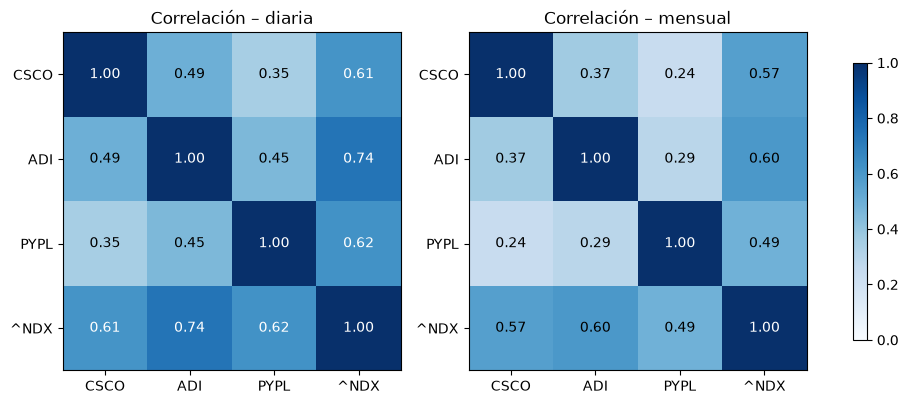

In [23]:
acc = ["CSCO", "ADI", "PYPL"]                            # solo las acciones entran a Markowitz

cov_d = r_d[acc].cov() * 252                             # Σ anual a partir de datos diarios
cov_m = r_m[acc].cov() * 12                              # Σ anual a partir de datos mensuales (comparación)
corr_d = r_d[activos].corr()                             # correlaciones diarias (incluye ^NDX)
corr_m = r_m[activos].corr()                             # correlaciones mensuales

cov_d.to_csv(PROC / "cov_anual_diaria.csv")              # insumo del Punto 3
cov_m.to_csv(PROC / "cov_anual_mensual.csv")             # insumo del Punto 4 (VaR mensual)
corr_d.to_csv(PROC / "corr_diaria.csv")

print(f"{'=' * 70}\nMATRIZ DE VARIANZAS-COVARIANZAS ANUAL (datos diarios × 252)")
display(cov_d.style.format("{:.4f}"))
print(f"{'=' * 70}\nMATRIZ DE VARIANZAS-COVARIANZAS ANUAL (datos mensuales × 12)")
display(cov_m.style.format("{:.4f}"))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))          # dos mapas de calor lado a lado
for a, (titulo, c) in zip(ax, [("Correlación – diaria", corr_d), ("Correlación – mensual", corr_m)]):
    im = a.imshow(c, cmap="Blues", vmin=0, vmax=1)        # color según el valor de ρ
    a.set_xticks(range(len(c)), c.columns); a.set_yticks(range(len(c)), c.index)
    for i in range(len(c)):
        for j in range(len(c)):
            a.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center",
                   color="white" if c.iloc[i, j] > 0.6 else "black")   # escribe ρ en cada celda
    a.set_title(titulo)
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

**Anualización de la matriz de covarianzas.** Se aplica la misma regla de la varianza: Σ_anual = Σ_diaria × 252 (o × 12 con datos mensuales). Como verificación, la diagonal de la matriz debe ser la volatilidad anual al cuadrado: CSCO 0.2667² = 0.0711 ✔. La correlación no se anualiza, porque es un número sin unidades.

### Interpretación de los resultados

**Retorno y riesgo individual.** En los últimos 10 años ADI fue la acción de mayor retorno anual (22.91 %), pero más volátil que CSCO (33.33 % frente a 26.67 %). Por su lado PYPL tuvo el retorno más bajo (3.31 %, inferior a la tasa libre de riesgo de 4.929 %) con la mayor volatilidad (39.73 %). El Nasdaq-100 obtuvo 19.51 % con solo 22.89 % de volatilidad, una mejor relación retorno/riesgo que cualquiera de las tres acciones por separado, a esto se le llama el efecto de la diversificación, si se hubiera invertido lo mejor sería seleccionar un ETF que replice el índice.

**Por qué la volatilidad diaria anualizada es mayor que la mensual?** Para las tres acciones y el índice, la volatilidad anualizada con datos diarios supera a la mensual entre 10 % y 20 % (ADI: 33.33 % frente a 27.99 %), aunque el retorno anual es casi idéntico. La regla de √k supone que los retornos son independientes entre sí. En la práctica, parte de los movimientos diarios son ruido de corto plazo y ese ruido infla la volatilidad diaria. Ninguna de las dos estimaciones es incorrecta: miden el riesgo a distinta medida del tiempo exigida. Por eso medimos cada una para que conecte con cada punto del laboratorio y se use la frecuencia correcta.

**Matriz de correlaciones.** Aunque la correlación diaria sea fuerte, ninguna correlación entre las acciones se acerca a 1:

| Par | ρ diaria | ρ mensual |
|---|---:|---:|
| CSCO – ADI | 0.49 | 0.37 |
| CSCO – PYPL | 0.35 | 0.24 |
| ADI – PYPL | 0.45 | 0.29 |

Esto confirma lo planteado anteriormente: al tener negocios distintos (redes, chips, pagos), las acciones no se mueven igual y combinarlas reduce el riesgo del portafolio.

Algo interesante a mencionar de como se comporta el mercado es que con datos mensuales las correlaciones suben gracias a que el corto plazo las tres acciones reaccionan juntas a las noticias del mercado, del día a día, mientras que en periodos de tiempos mensuales cada una se relacionan más con sus fundamentales.

**Relación con el mercado.** La correlación con el ^NDX es de 0.74 para ADI, 0.62 para PYPL y 0.61 para CSCO. ADI es la que más se correlaciona con el índice, además de ser la más volátil y la de mayor retorno, esta tendrá la beta más alta (Punto 5) y será la que más aumente el número de contratos de futuros necesarios para la cobertura.

## Punto 3 – Portafolio óptimo de Markowitz: GMV y Máximo Sharpe (R3 – 7 %)

In [26]:
from scipy.optimize import minimize

rf = 0.04929                                       # ^TNX al 30/10/2026
CAPITAL = 35_000_000                               # USD a invertir
mu = np.exp(r_d[acc].mean() * 252) - 1             # retornos anuales esperados (2.1, diaria)
S = cov_d.values                                   # matriz Σ anual (2.2, diaria × 252)
cotas = [(0.15, 0.45)] * len(acc)                  # peso mínimo 15 % y máximo 45 % por acción
restr = {"type": "eq", "fun": lambda w: w.sum() - 1}   # la suma de pesos debe ser 100 %
w0 = np.repeat(1 / len(acc), len(acc))             # punto de partida: pesos iguales (semilla)

def ret_p(w): return w @ mu.values                 # E(rp) = Σ wi·μi
def vol_p(w): return np.sqrt(w @ S @ w)            # σp = √(wᵀ Σ w)
def sharpe(w): return (ret_p(w) - rf) / vol_p(w)   # Sp = (E(rp) − rf) / σp

gmv = minimize(vol_p, w0, method="SLSQP", bounds=cotas, constraints=restr)               # mínima σp
msr = minimize(lambda w: -sharpe(w), w0, method="SLSQP", bounds=cotas, constraints=restr) # máximo Sp
assert gmv.success and msr.success, "La optimización no convergió"

def resumen(w):                                    # arma la ficha de un portafolio
    return pd.Series({**{f"Peso {a}": x for a, x in zip(acc, w)},
                      **{f"Monto {a} (USD)": x * CAPITAL for a, x in zip(acc, w)},
                      "Monto total (USD)": w.sum() * CAPITAL,
                      "Retorno esperado": ret_p(w), "Desv. estándar": vol_p(w), "Sharpe": sharpe(w)})

port = pd.DataFrame({"GMV": resumen(gmv.x), "Máx. Sharpe": resumen(msr.x)})
port.to_csv(PROC / "portafolios_markowitz.csv")    # insumo de los Puntos 4 a 12

def fmt_fila(fila, v):                             # formato según el tipo de fila
    if fila.startswith("Monto"): return f"{v:,.2f}"                       # USD: 15,750,000.00
    if fila == "Sharpe": return f"{v:.4f}"
    return f"{v:.2%}"                                                     # pesos, retorno y riesgo
tabla_p3 = pd.DataFrame({c: [fmt_fila(i, port.at[i, c]) for i in port.index] for c in port},
                        index=port.index)
print(f"{'=' * 80}\nPORTAFOLIOS ÓPTIMOS · r_f = {rf:.3%} · capital USD {CAPITAL:,.0f} · pesos 15% – 45%")
display(tabla_p3)

PORTAFOLIOS ÓPTIMOS · r_f = 4.929% · capital USD 35,000,000 · pesos 15% – 45%


,GMV,Máx. Sharpe
Peso CSCO,45.00%,40.00%
Peso ADI,33.97%,45.00%
Peso PYPL,21.03%,15.00%
Monto CSCO (USD),"15,750,000.00","14,000,000.00"
Monto ADI (USD),"11,889,583.81","15,750,000.00"
Monto PYPL (USD),"7,360,416.19","5,250,000.00"
Monto total (USD),"35,000,000.00","35,000,000.00"
Retorno esperado,15.88%,17.39%
Desv. estándar,25.12%,25.63%
Sharpe,0.4359,0.4860


**Portafolios óptimos:** Para efectos del ejercicio, optamos por tener una restricción de pesos entre 15 % y 45 %, el portafolio de mínima varianza (GMV) asigna 45.00 % a CSCO, 33.97 % a ADI y 21.03 % a PYPL, con una volatilidad de 25.12 % y un retorno esperado de 15.88 %. El de Máximo Sharpe asigna 40.00 % a CSCO, 45.00 % a ADI y 15.00 % a PYPL, con 17.39 % de retorno, 25.63 % de volatilidad y un Sharpe de 0.4860.

Las restricciones se activan en ambos casos: CSCO queda en el techo del portafolio de mínima varianza y ADI en el techo y PYPL en el piso del Máximo Sharpe. Sin restricciones, el Máximo Sharpe excluiría a PYPL, porque su retorno histórico (3.31 %) es inferior a la tasa libre de riesgo.

La acción de PYPL se queda por la diversificación, reduce el riesgo en unos 6 puntos porcentuales frente al promedio ponderado de las volatilidades individuales: ambos portafolios son menos volátiles que CSCO, la acción menos riesgosa.

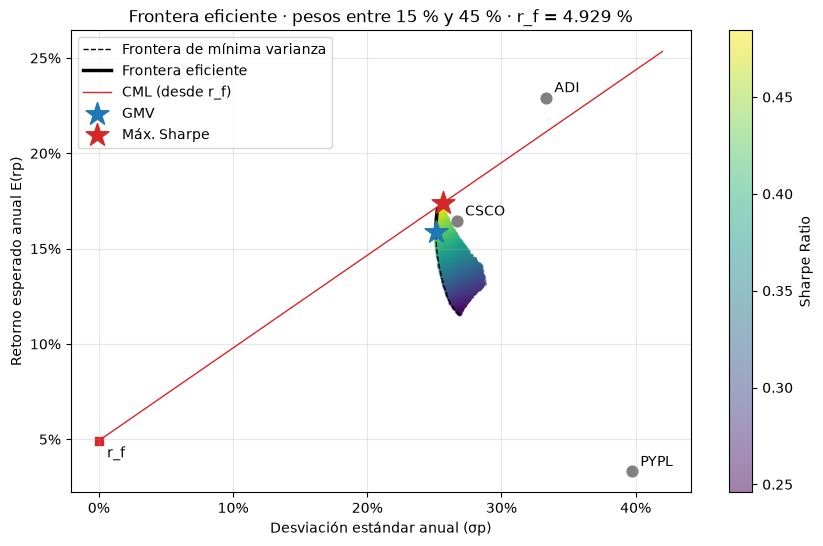

Retorno factible con las restricciones: 11.50% – 17.39%


In [32]:
# Rango de retornos alcanzables con las restricciones de 15 %–45 %
r_lo = minimize(ret_p, w0, method="SLSQP", bounds=cotas, constraints=restr).fun            # retorno mínimo
r_hi = -minimize(lambda w: -ret_p(w), w0, method="SLSQP", bounds=cotas, constraints=restr).fun  # retorno máximo

frontera = []                                                    # (σ, E(r)) de cada punto de la curva
for R in np.linspace(r_lo, r_hi, 60):                            # 60 retornos objetivo
    c = [restr, {"type": "eq", "fun": lambda w, R=R: ret_p(w) - R}]   # exige E(rp) = R
    res = minimize(vol_p, w0, method="SLSQP", bounds=cotas, constraints=c)
    if res.success: frontera.append((res.fun, R))
frontera = np.array(frontera)
eficiente = frontera[frontera[:, 1] >= ret_p(gmv.x) - 1e-9]      # tramo por encima del GMV

rng = np.random.default_rng(42)                                  # semilla: resultado reproducible
W = rng.dirichlet(np.ones(len(acc)), 30_000)                     # pesos aleatorios que suman 1
W = W[((W >= 0.15) & (W <= 0.45)).all(axis=1)]                   # deja solo los que cumplen los límites
nube_r = W @ mu.values                                           # retorno de cada portafolio aleatorio
nube_s = np.sqrt(np.einsum("ij,jk,ik->i", W, S, W))              # riesgo de cada portafolio aleatorio

fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(nube_s, nube_r, c=(nube_r - rf) / nube_s, cmap="viridis", s=4, alpha=0.5)
fig.colorbar(sc, label="Sharpe Ratio")
ax.plot(frontera[:, 0], frontera[:, 1], "k--", lw=1, label="Frontera de mínima varianza")
ax.plot(eficiente[:, 0], eficiente[:, 1], "k-", lw=2.5, label="Frontera eficiente")
x_cml = np.linspace(0, 0.42, 50)
ax.plot(x_cml, rf + sharpe(msr.x) * x_cml, color="tab:red", lw=1, label="CML (desde r_f)")
for a in acc:                                                    # acciones individuales
    ax.scatter(np.sqrt(cov_d.loc[a, a]), mu[a], marker="o", s=60, color="grey")
    ax.annotate(a, (np.sqrt(cov_d.loc[a, a]), mu[a]), xytext=(6, 4), textcoords="offset points")
ax.scatter(vol_p(gmv.x), ret_p(gmv.x), marker="*", s=300, color="tab:blue", label="GMV", zorder=5)
ax.scatter(vol_p(msr.x), ret_p(msr.x), marker="*", s=300, color="tab:red", label="Máx. Sharpe", zorder=5)
ax.scatter(0, rf, marker="s", color="tab:red"); ax.annotate("r_f", (0, rf), xytext=(6, -12), textcoords="offset points")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Desviación estándar anual (σp)"); ax.set_ylabel("Retorno esperado anual E(rp)")
ax.set_title("Frontera eficiente · pesos entre 15 % y 45 % · r_f = 4.929 %")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.savefig("../outputs/figures/frontera_eficiente.png", dpi=150, bbox_inches="tight")  # para el informe APA
plt.show()
print(f"Retorno factible con las restricciones: {r_lo:.2%} – {r_hi:.2%}")

**Portafolio definitivo: Máximo Sharpe** (CSCO 40 % · ADI 45 % · PYPL 15 %).

Se eligió el portafolio de Máximo Sharpe sobre el de mínima varianza por cuatro razones:

| Criterio | GMV | Máx. Sharpe |
| :--- | :--- | :--- |
| **Retorno esperado** | 15.88 % (≈ USD 5.56 M/año) | 17.39 % (≈ USD 6.09 M/año) |
| **Volatilidad** | 25.12 % | 25.63 % (+0.51 pp) |
| **Sharpe** | 0.4359 | 0.4860 |
| **Concentración** | CSCO en el techo (45 %) | ADI en el techo (45 %), PYPL en el piso (15 %) |
| **Objetivo del gerente (4 años con cobertura)** | Prioriza el menor riesgo | La cobertura con futuros ya reduce el riesgo de mercado, así que conviene elegir el portafolio más eficiente (mejor Sharpe) |

*Limitación:* el portafolio depende de retornos esperados históricos, la restricción de 15 %–45 % reduce su Sharpe frente al óptimo sin límites (0.57), a cambio de evitar concentrar el capital.

## Punto 4 – VaR mensual al 1 % y 5 % (R5 – 8 %)

VaR MENSUAL PARAMÉTRICO · Máximo Sharpe · V0 = USD 35,000,000
μ mensual = 1.3182% · σ mensual = 6.0200% · ganancia esperada del mes ≈ USD 464,433


,α (VaR al),z,Retorno crítico (log),VaR (%),VaR (USD)
VaR 95%,5%,1.6449,-8.5837%,8.23%,"2,878,978.61"
VaR 99%,1%,2.3263,-12.6863%,11.91%,"4,170,100.79"


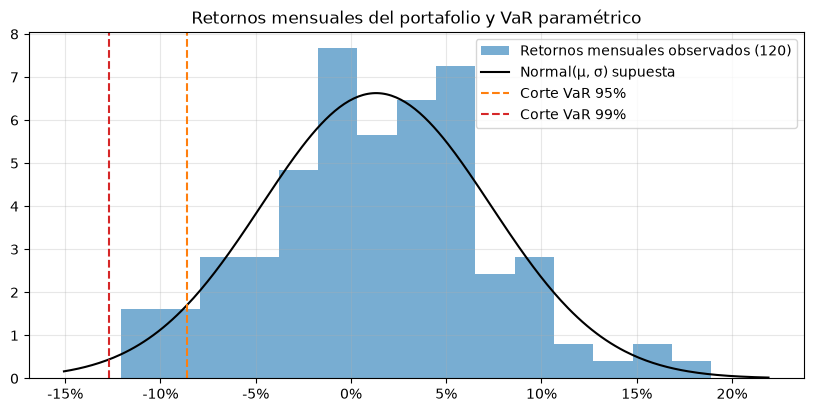

In [40]:
from scipy.stats import norm

w_opt = msr.x                                      # pesos del Máximo Sharpe (40 / 45 / 15)
V0 = CAPITAL                                       # valor inicial: USD 35,000,000
rp_m = r_m[acc] @ w_opt                            # retorno log mensual del portafolio (120 meses)
mu_m, sig_m = rp_m.mean(), rp_m.std()              # μ y σ mensuales del portafolio

filas = {}
for c in [0.95, 0.99]:                             # niveles de confianza
    z = norm.ppf(c)                                # 1.645 y 2.326
    r_crit = mu_m - z * sig_m                      # retorno crítico: peor caso al c %
    filas[f"VaR {c:.0%}"] = {
        "α (VaR al)": 1 - c, "z": z, "Retorno crítico (log)": r_crit,
        "VaR (%)": 1 - np.exp(r_crit),             # pérdida porcentual: 1 − e^(r*)
        "VaR (USD)": V0 * (1 - np.exp(r_crit)),    # pérdida en dólares sobre USD 35 M
    }
var_tab = pd.DataFrame(filas).T
var_tab.to_csv(PROC / "var_mensual.csv")           # insumo de los Puntos 10 y 11

print(f"{'=' * 70}\nVaR MENSUAL PARAMÉTRICO · Máximo Sharpe · V0 = USD {V0:,.0f}")
print(f"μ mensual = {mu_m:.4%} · σ mensual = {sig_m:.4%} · ganancia esperada del mes ≈ USD {V0*(np.exp(mu_m)-1):,.0f}")
display(var_tab.style.format({"α (VaR al)": "{:.0%}", "z": "{:.4f}", "Retorno crítico (log)": "{:.4%}",
                              "VaR (%)": "{:.2%}", "VaR (USD)": "{:,.2f}"}))

fig, ax = plt.subplots(figsize=(10, 4.5))          # distribución de retornos mensuales y cortes del VaR
ax.hist(rp_m, bins=15, density=True, alpha=0.6, label="Retornos mensuales observados (120)")
x = np.linspace(rp_m.min() - 0.03, rp_m.max() + 0.03, 300)
ax.plot(x, norm.pdf(x, mu_m, sig_m), "k-", label="Normal(μ, σ) supuesta")
for c, col in [(0.95, "tab:orange"), (0.99, "tab:red")]:
    ax.axvline(filas[f"VaR {c:.0%}"]["Retorno crítico (log)"], color=col, ls="--", label=f"Corte VaR {c:.0%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Retornos mensuales del portafolio y VaR paramétrico"); ax.legend(); ax.grid(alpha=0.3)
fig.savefig("../outputs/figures/var_mensual.png", dpi=150, bbox_inches="tight"); plt.show()

**VaR mensual:** El portafolio de Máximo Sharpe (USD 35,000,000) tiene un retorno log mensual esperado de 1.32 % (≈ USD 464,433) y una volatilidad mensual de 6.02 %. Bajo el supuesto de normalidad:

- **VaR 95 % (al 5 %): 8.23 % ≈ USD 2,878,979.** En 19 de cada 20 meses la pérdida no debería superar este monto; en el mes restante podría ser mayor.
- **VaR 99 % (al 1 %): 11.91 % ≈ USD 4,170,101.** Es la pérdida de un mes extremo, que ocurriría 1 vez cada 100 meses.

Un solo mes adverso al 95 % borraría más de seis meses de ganancia esperada. El modelo es consistente con la historia: en los últimos 120 meses el VaR 95 % fue superado 7 veces (se esperaban 6) y el VaR 99 % ninguna. La peor pérdida fue −12.07 % en abril de 2022, durante la caída del mercado tecnológico.

**Relación con la cobertura.** El VaR mide el riesgo total del portafolio. Alrededor del 56 % de su varianza mensual se explica por el Nasdaq-100 (R² frente al ^NDX), y es esa parte sistemática la que se puede neutralizar con futuros sobre el índice. El 44 % restante es riesgo específico de CSCO, ADI y PYPL, que la cobertura con futuros no elimina. Por eso el número de contratos (Punto 6) se determina con la beta del portafolio sobre su valor total (USD 35 M), y el VaR sirve como referencia de la pérdida que la cobertura busca compensar.

## Punto 5 – Betas CAPM y beta del portafolio (R6 – 8 %)